# Contexto, Problema de Negócio e Hipótese

A lavagem de dinheiro é um dos crimes financeiros mais sofisticados e difíceis de detectar. Os sistemas tradicionais de prevenção (baseados em regras estáticas ou modelos tabulares isolados) sofrem com dois grandes gargalos:
- **Alta Taxa de Falsos Positivos:** Regras simples geram alertas em massa para transações legítimas.
- **Cegueira Estrutural:** Modelos tradicionais olham apenas para transações isoladas (remetente e destinatário), falhando em enxergar a rede de conexões, ou seja, os anéis criminosos, as contas-laranja (*mule accounts*) intermediárias e as táticas de fragmentação de capital (*smurfing*).

---

## Nossa Hipótese Central

Modelos tradicionais baseados apenas no comportamento transacional isolado (quanto a pessoa pagou e como pagou) falham em detectar lavagem de dinheiro porque os criminosos fragmentam os valores (smurfing). A verdadeira inteligência preditiva surge quando analisamos a **topologia da rede** — ou seja, quem está conectado a quem e qual é o papel estrutural da conta no ecossistema.

In [3]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configuração de estilo visual corporativo para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Conectando ao banco SQLite criado na Fase 1
DB_PATH = "../data/aml_network.db"
conn = sqlite3.connect(DB_PATH)

print("Conectado ao banco SQLite com sucesso.")

# Verificando contagem macro de registros
df_trans_count = pd.read_sql("SELECT COUNT(*) as total_transacoes FROM transacoes", conn)
df_acc_count = pd.read_sql("SELECT COUNT(*) as total_contas FROM contas", conn)

print(f"Total de Transações na Base: {df_trans_count['total_transacoes'].iloc[0]:,}")
print(f"Total de Contas Cadastradas: {df_acc_count['total_contas'].iloc[0]:,}")


Conectado ao banco SQLite com sucesso.
Total de Transações na Base: 5,078,345
Total de Contas Cadastradas: 518,581


## Fase 2: Análise Exploratória (EDA)
Antes de construir grafos cegamente, precisamos **investigar os dados crus** para responder a perguntas como: 
1. Qual é o tamanho real do desbalanceamento (a agulha no palheiro)?
2. Como o dinheiro se comporta? Os criminosos usam canais específicos ou espalham em tudo?
3. Existem padrões ocultos de valores ou modalidades que justifiquem a nossa tese?

---

#### Auditoria de Estrutura e Integridade dos Dados
Antes de qualquer análise estatística, precisamos investigar a estrutura da tabela de transações para entender quais colunas temos à disposição e se o banco possui problemas de dados corrompidos ou nulos.

In [4]:
print("Inspecionando o Schema da Tabela 'transacoes':")
df_colunas = pd.read_sql("PRAGMA table_info(transacoes);", conn)
display(df_colunas)

Inspecionando o Schema da Tabela 'transacoes':


,cid,name,type,notnull,dflt_value,pk
0,0,Timestamp,TEXT,0,None,0
1,1,From_Bank,INTEGER,0,None,0
2,2,Account,TEXT,0,None,0
3,3,To_Bank,INTEGER,0,None,0
4,4,Account.1,TEXT,0,None,0
5,5,Amount_Received,REAL,0,None,0
6,6,Receiving_Currency,TEXT,0,None,0
7,7,Amount_Paid,REAL,0,None,0
8,8,Payment_Currency,TEXT,0,None,0
9,9,Payment_Format,TEXT,0,None,0


##### Mapeamento do Schema: Entendendo as Colunas da Base

Analisando o schema retornado pelo banco (`PRAGMA table_info`), temos 11 colunas que compõem o ciclo de vida de cada transação. Para guiar nossa investigação, vamos agrupá-las por relevância analítica:

1. **O Núcleo da Nossa Análise (Foco de Redes e Grafos):**
   - `Account` e `Account.1`: Identificam os nós de origem e destino. São as colunas vitais para construirmos o Grafo na Fase 3.
   - `Amount_Paid` e `Amount_Received`: Os montantes financeiros movimentados, fundamentais para a análise econômica.
   - `Payment_Format`: O canal ou meio utilizado na operação.

2. **A Variável-Alvo (Ground Truth):**
   - `Is_Laundering`: A flag de auditoria da base (fornecida pela simulação da IBM). Ela assume valor `1` quando a transação comprovadamente faz parte de um esquema de lavagem de dinheiro simulado e `0` para operações legítimas. É o nosso alvo preditivo.

3. **Colunas de Contexto e Apoio:**
   - `From_Bank` e `To_Bank`: As instituições financeiras de origem e destino.
   - `Payment_Currency` e `Receiving_Currency`: As moedas utilizadas na ponta de pagamento e recebimento.
   - `Timestamp`: O carimbo temporal da operação.

##### Vamos auditar se existem valores ausentes nas colunas críticas para garantir a integridade da base antes de avançarmos.

In [28]:
# Investigando se existem valores nulos nas colunas críticas
query_nulls = """
    SELECT 
        SUM(CASE WHEN Amount_Paid IS NULL THEN 1 ELSE 0 END) as null_amount,
        SUM(CASE WHEN Is_Laundering IS NULL THEN 1 ELSE 0 END) as null_laundering,
        SUM(CASE WHEN Payment_Format IS NULL THEN 1 ELSE 0 END) as null_format
    FROM transacoes;
"""
df_nulls = pd.read_sql(query_nulls, conn)
print("\nVerificando integridade (valores nulos):")
display(df_nulls)


Verificando integridade (valores nulos):


,null_amount,null_laundering,null_format
0,0,0,0


**Verificação de Integridade:** A base possui **zero valores nulos** nas colunas críticas de montante, formato de pagamento e na nossa variável-alvo (`Is_Laundering`). Isso nos poupa de etapas complexas de imputação de dados e garante bases limpas para as próximas fases.

##### O Coração do Problema: Qual é a Proporção de Fraudes?

Toda análise de dados baseada no mercado de risco financeiro precisa responder à pergunta de ouro: *Qual é o tamanho do problema?* Vamos investigar a distribuição da coluna `Is_Laundering` para entender o nível de desbalanceamento das classes.

,Is_Laundering,qtd_transacoes,percentual
0,0,5073168,99.8981
1,1,5177,0.1019


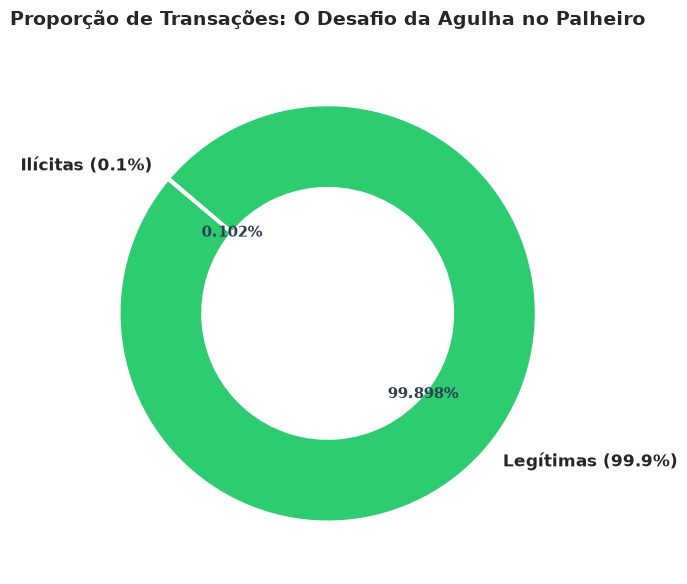

In [5]:
# Investigando a distribuição do target
query_target = """
    SELECT 
        Is_Laundering, 
        COUNT(*) as qtd_transacoes, 
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM transacoes), 4) as percentual 
    FROM transacoes
    GROUP BY Is_Laundering;
"""

df_laundering = pd.read_sql(query_target, conn)
display(df_laundering)

# Gerando a visualização para dimensionar o abismo do desbalanceamento
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#2ecc71', '#e74c3c']  # Verde para legítimas, Vermelho vivo para ilícitas
labels = ['Legítimas (99.9%)', 'Ilícitas (0.1%)']

wedges, texts, autotexts = ax.pie(
    df_laundering['qtd_transacoes'],
    labels=labels,
    autopct='%1.3f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)

plt.setp(autotexts, size=11, weight="bold", color="#2c3e50")
plt.setp(texts, size=12, weight="bold")
ax.set_title("Proporção de Transações: O Desafio da Agulha no Palheiro", fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

**Proporção das Fraudes:** O resultado é um retrato da assimetria em crimes financeiros:

- Do total de mais de **5 milhões de transações**, apenas **5.177 registros (0,1019%)** são classificados como lavagem de dinheiro (`Is_Laundering = 1`).
Esse desbalanceamento extremo explica por que sistemas tabulares baseados em acurácia falham. Se um modelo simples prever que *tudo é legítimo*, ele terá 99,90% de acurácia, mas deixará passar todo o crime. 

É exatamente essa barreira estatística que justifica a nossa migração para **Teoria de Grafos nas Fases 3 e 4**, onde o foco deixa de ser a transação isolada e passa a ser a topologia da rede de conexões.

##### Investigando o Perfil Transacional: Como o Crime Movimenta Dinheiro?
Será que todas as modalidades de pagamento (`Payment_Format`) são utilizadas da mesma forma pelos criminosos, ou existe um canal favorito? 

Vamos cruzar os dados para ver onde o volume ilícito se concentra e qual é o comportamento do *ticket médio* entre operações legítimas e ilícitas.

In [19]:
# Consulta agregando modalidades, contagens e valores médios comparativos
query_modalidades = """
    SELECT 
        Payment_Format,
        COUNT(*) as total_transacoes,
        SUM(CASE WHEN Is_Laundering = 1 THEN 1 ELSE 0 END) as transacoes_ilicitas,
        ROUND(AVG(Amount_Paid), 2) as valor_medio_geral,
        ROUND(AVG(CASE WHEN Is_Laundering = 1 THEN Amount_Paid ELSE NULL END), 2) as valor_medio_ilicito,
        ROUND(AVG(CASE WHEN Is_Laundering = 0 THEN Amount_Paid ELSE NULL END), 2) as valor_medio_legitimo
    FROM transacoes
    GROUP BY Payment_Format
    ORDER BY transacoes_ilicitas DESC;
"""

df_modalidades = pd.read_sql(query_modalidades, conn)
display(df_modalidades)

,Payment_Format,total_transacoes,transacoes_ilicitas,valor_medio_geral,valor_medio_ilicito,valor_medio_legitimo
0,ACH,600797,4483,9497986.77,41631395.48,9256412.58
1,Cheque,1864331,324,6103601.28,550989.94,6104566.43
2,Credit Card,1323324,206,86783.37,24462.43,86793.07
3,Cash,490891,108,7359934.25,2364778.06,7361033.47
4,Bitcoin,146091,56,30.83,0.63,30.84
5,Wire,171855,0,4876399.53,NaN,4876399.53
6,Reinvestment,481056,0,2595009.06,NaN,2595009.06


Analisando a tabela acima, descobrimos padrões comportamentais fascinantes:

1. **A Hegemonia do ACH:** O canal **ACH** (Automated Clearing House) concentra de forma isolada a esmagadora maioria das transações ilícitas da base.

2. **A Assimetria do Ticket Médio:** Quando olhamos para o valor das operações no ACH, percebemos que o ticket médio ilícito dispara para impressionantes **41.6 milhões**, enquanto as operações legítimas no mesmo canal giram em torno de 9.2 milhões. Isso indica que o ACH é a via preferencial escolhida pelos criminosos para movimentar blocos massivos de capital.

3. **O Contraste do *Smurfing*:** Em contrapartida, canais como Bitcoin e Cartões de Crédito registram valores ilícitos muito baixos, sugerindo táticas de fragmentação (*smurfing*) para burlar limites de monitoramento tradicional.

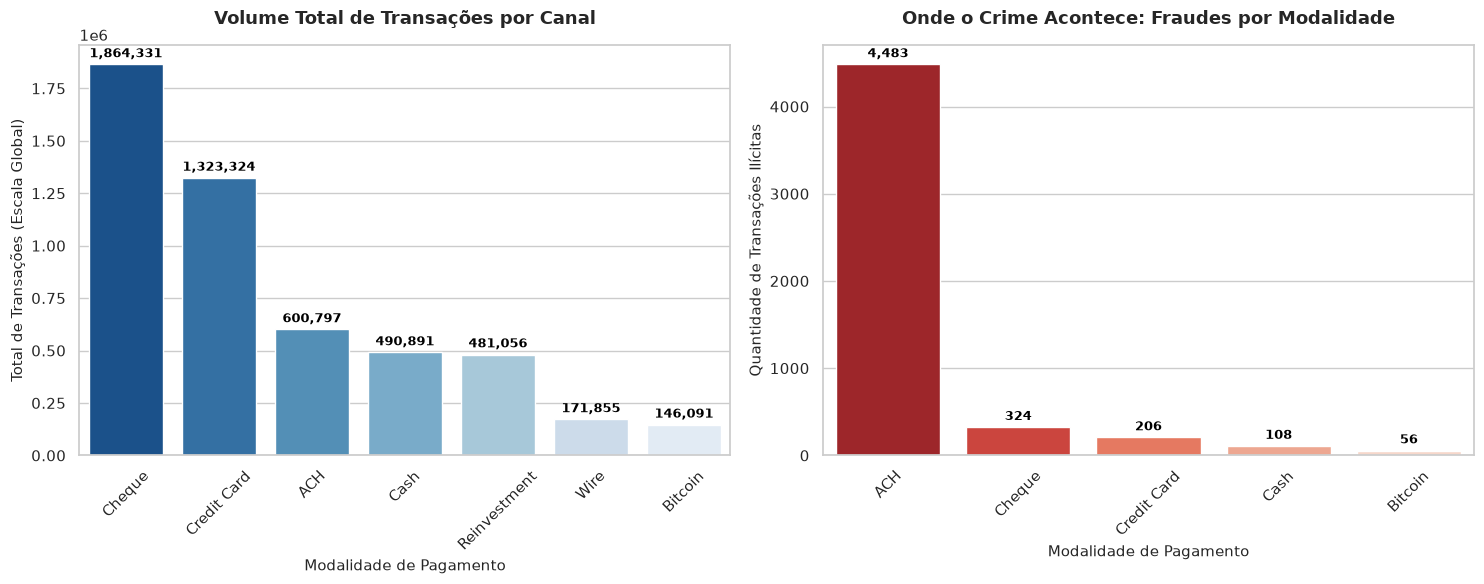

In [30]:
# Criando uma visualização lado a lado para comparar Volume Geral vs. Fraude por Modalidade com rótulos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Onde o volume geral de transações flui
df_sorted_total = df_modalidades.sort_values(by='total_transacoes', ascending=False)
sns.barplot(
    data=df_sorted_total,
    x='Payment_Format',
    y='total_transacoes',
    ax=ax1,
    palette='Blues_r',
    hue='Payment_Format',
    legend=False
)
ax1.set_title("Volume Total de Transações por Canal", fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel("Modalidade de Pagamento", fontsize=11)
ax1.set_ylabel("Total de Transações (Escala Global)", fontsize=11)
ax1.tick_params(axis='x', rotation=45)

# Adicionando rótulos de valor no Gráfico 1
for p in ax1.patches:
    height = p.get_height() # type: ignore
    if height > 0:
        ax1.annotate(f"{int(height):,}",
                    (p.get_x() + p.get_width() / 2., height), # type: ignore
                    ha='center', va='bottom',
                    xytext=(0, 3), textcoords='offset points',
                    fontsize=9, fontweight='bold', color='black')

# Gráfico 2: Onde a fraude (Is_Laundering = 1) se concentra de fato
df_ilicitas_plot = df_modalidades[df_modalidades['transacoes_ilicitas'] > 0].sort_values(by='transacoes_ilicitas', ascending=False)
sns.barplot(
    data=df_ilicitas_plot,
    x='Payment_Format',
    y='transacoes_ilicitas',
    ax=ax2,
    palette='Reds_r',
    hue='Payment_Format',
    legend=False
)
ax2.set_title("Onde o Crime Acontece: Fraudes por Modalidade", fontsize=13, fontweight='bold', pad=15)
ax2.set_xlabel("Modalidade de Pagamento", fontsize=11)
ax2.set_ylabel("Quantidade de Transações Ilícitas", fontsize=11)
ax2.tick_params(axis='x', rotation=45)

# Adicionando rótulos de valor no Gráfico 2
for p in ax2.patches:
    height = p.get_height() # type: ignore
    if height > 0:
        ax2.annotate(f"{int(height):,}",
                    (p.get_x() + p.get_width() / 2., height), # type: ignore
                    ha='center', va='bottom',
                    xytext=(0, 3), textcoords='offset points',
                    fontsize=9, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

Ao comparar os dois painéis lado a lado, o contraste é revelador:

Enquanto o ecossistema geral é dominado por *Cheque* e *Credit Card* em volume bruto de transações, esses canais **não** são os maiores vetores de lavagem de dinheiro. O crime se direciona para o canal **ACH**, que concentra o pico de transações ilícitas acompanhado do ticket médio milionário que descobrimos na tabela. 

Essa desconexão entre "onde as pessoas comuns pagam" e "onde os criminosos operam" reforça por que regras ingênuas baseadas apenas em volume falham.

---

## Conclusão da EDA: O Limite da Análise Tabular

Os dados confirmam a nossa hipótese inicial: embora variáveis isoladas como o formato de pagamento (ex: a concentração de grandes somas no ACH) nos dêem pistas valiosas, elas tratam o crime de forma fragmentada. 

A lavagem de dinheiro é um fenômeno coletivo e estrutural. Por isso, encerrar a EDA aqui nos leva ao próximo passo: na Fase 3 (`03_grafo_e_centralidade.ipynb`), vamos conectar os pontos, transformar essa massa de transações em um **Grafo Direcionado**, e calcular as métricas topológicas para expor as contas-laranja (*mule accounts*) operando nas sombras da rede.